In [2]:
import os
import pickle
import sys
import threading
import time

import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config

root_dir = os.path.abspath("..")
os.environ["PYTHONPATH"] = root_dir + os.pathsep + os.environ.get("PYTHONPATH", "")  # parallel workers import the library too
data_dir = os.path.join(root_dir, "data")
figs_dir = os.path.join(root_dir, "figs")
os.makedirs(data_dir, exist_ok=True)
if root_dir not in sys.path:
    sys.path.append(root_dir)

from current_setpoints.models.machines import ieee_machine2_trained_neural_flux_and_torque
from current_setpoints.models.forward_model import ForwardModel, Fault, count_peaks_at_limit
from current_setpoints.optimization import ActiveSetOptimizer, calculate_grid


def call_with_timeout(timeout, fn, *args, **kwargs):
    """Plain daemon thread, same mechanism as grid.py's _call_with_timeout."""
    result = {}

    def _run():
        try:
            result["value"] = fn(*args, **kwargs)
        except Exception as exc:
            result["error"] = exc

    t = threading.Thread(target=_run, daemon=True)
    t.start()
    t.join(timeout)
    if t.is_alive():
        return None, "timeout"
    if "error" in result:
        return None, f"exception: {result['error']!r}"
    return result.get("value"), None

In [3]:
# Dynamic fault-tolerant torque-speed maps (open-circuit faults), "_tauR" model, problem (9) + Algorithm 1
# (library ActiveSetOptimizer). Open-phase constraint per node: the open phase's current through the healthy
# phase map is zero -- PDF 11 sec. 8 N R(theta_n) i_n = 0 plus the zero-sum condition of the isolated star
# point (kept for now, see docs note, to confirm with the supervisor). Static fault modes are not used.
QUICK = os.environ.get("FAULT_MAPS_QUICK") == "1"  # tiny smoke test

CURR_MAX = 30.0
VOLT_MAX = 13.0
OMEGA_MAX = 1800.0  # mechanical RPM
SLSQP_OPTS = {"disp": False, "ftol": 1e-8, "maxiter": 500}
N_GRID = 30 if QUICK else 60
N_TORQ = 3 if QUICK else 23
N_OMEGA = 3 if QUICK else 23
COARSE_TOP = 0.8  # torque targets: coarse 0..0.8, then fine 0.8..1.02 of each case's own dynamic max torque
TORQ_TOP = 1.02
PROBE_TIMEOUT_SECONDS = 900
CELL_TIMEOUT_SECONDS = 900
SAVE_POINT_PNGS = not QUICK  # 9-panel waveform figure for every grid point

SCENARIOS = {"one_fault": (0,), "two_adjacent": (0, 1), "two_nonadjacent": (0, 2)}

MODEL_TAG = "tauR"
run_tag = f"{N_TORQ}x{N_OMEGA}_N{N_GRID}_{MODEL_TAG}" + ("_quick" if QUICK else "")
summary_dir = os.path.join(figs_dir, f"fault_maps_dynamic_summary_{run_tag}")
os.makedirs(summary_dir, exist_ok=True)
drive = ieee_machine2_trained_neural_flux_and_torque(curr_max=CURR_MAX, volt_max=VOLT_MAX)
const_mech_speed = 30.0 / (np.pi * drive.n_ppairs)
dim = drive.dim
vec_omega = np.linspace(0.0, OMEGA_MAX / const_mech_speed, N_OMEGA)
rpm_vec = vec_omega * const_mech_speed
n_coarse = max(2, round(N_TORQ * 9 / 25))
n_fine = N_TORQ - n_coarse
frac = np.concatenate([np.linspace(0.0, COARSE_TOP, n_coarse),
                       COARSE_TOP + (TORQ_TOP - COARSE_TOP) * np.arange(1, n_fine + 1) / n_fine])
print(f"dynamic fault maps, model {MODEL_TAG}, N_GRID={N_GRID}, grid {N_TORQ}x{N_OMEGA}, run tag {run_tag}")

dynamic fault maps, model tauR, N_GRID=60, grid 23x23, run tag 23x23_N60_tauR


In [4]:
PHASE_LETTERS = ["a", "b", "c", "d", "e"]


def segment_label(n_curr, n_volt):
    roman = {0: "", 1: "I", 2: "II"}
    return f"MTPA_{n_curr}" if n_volt == 0 else f"FW_{roman[n_volt]},{n_curr}"


def fine_idx_grid(fwd, theta_grid):
    n_theta = fwd.vec_theta.size - 1
    return np.round(theta_grid / (2 * np.pi) * n_theta).astype(int) % n_theta


def alpha_beta_xy(theta_grid, sched):
    c1, s1 = np.cos(theta_grid), np.sin(theta_grid)
    c3, s3 = np.cos(3 * theta_grid), np.sin(3 * theta_grid)
    id1, iq1, id3, iq3 = sched[:, 0], sched[:, 1], sched[:, 2], sched[:, 3]
    i_alpha = c1 * id1 - s1 * iq1
    i_beta = s1 * id1 + c1 * iq1
    i_x = c3 * id3 - s3 * iq3
    i_y = s3 * id3 + c3 * iq3
    return i_alpha, i_beta, i_x, i_y


def waveforms_for_plot(fwd, omega, curr_dq, n_theta_plot=360):
    """(theta_deg, sched, iph, vph, theta_v_deg) for either a constant (static, curr_dq.ndim==1)
    or per-node-trajectory (dynamic, curr_dq.ndim==2) current, on a common convention suitable
    for the 9-panel diagnostic plot. Static is swept fresh over n_theta_plot samples of the
    SAME constant vector (current doesn't change over the cycle, only its phase reconstruction
    does, since the dq->phase map itself rotates with theta); dynamic reuses each node's own
    angle/current directly.

    Dynamic voltage: PDF eq. (7) with the current running linearly between nodes, i.e. WITH the
    dynamic term (omega/dtheta) L (i_next - i_n) -- two values per node, just before theta_n (end
    of the incoming segment) and just after it (start of the outgoing one), the same voltages
    ActiveSetOptimizer limits and grid.py's _trajectory_waveforms reports. vph then has 2 columns
    per node, plotted against theta_v_deg (each node angle twice)."""
    kept = list(fwd.fault._kept)
    dynamic = curr_dq.ndim == 2
    if not dynamic:
        theta_grid = np.linspace(0.0, 2 * np.pi, n_theta_plot, endpoint=False)
        sched = np.tile(curr_dq, (n_theta_plot, 1))
        idx_grid = fine_idx_grid(fwd, theta_grid)
        n_pts = n_theta_plot
    else:
        n_pts = curr_dq.shape[0]
        theta_grid = np.linspace(0.0, 2 * np.pi, n_pts, endpoint=False)
        idx_grid = fine_idx_grid(fwd, theta_grid)
        sched = curr_dq
    coupling = omega / (2 * np.pi / n_pts)  # omega / dtheta (dynamic only)

    iph = np.full((len(kept), n_pts), np.nan)
    vph = np.full((len(kept), 2 * n_pts if dynamic else n_pts), np.nan)
    for k, ti in enumerate(idx_grid):
        i_n = sched[k]
        if not np.all(np.isfinite(i_n)):
            continue
        iph[:, k] = fwd.phase_map_at_theta(int(ti)) @ i_n
        gU, gL, bV = fwd.volt_map_at_theta(int(ti), omega, i_n)
        v_steady = gU @ i_n + bV
        if dynamic:
            i_prev, i_next = sched[(k - 1) % n_pts], sched[(k + 1) % n_pts]
            vph[:, 2 * k] = (v_steady + coupling * (gL @ (i_n - i_prev)))[kept]
            vph[:, 2 * k + 1] = (v_steady + coupling * (gL @ (i_next - i_n)))[kept]
        else:
            vph[:, k] = v_steady[kept]
    theta_deg = np.rad2deg(theta_grid)
    theta_v_deg = np.repeat(theta_deg, 2) if dynamic else theta_deg
    return theta_deg, sched, iph, vph, theta_v_deg


def classify_status(sol):
    if sol is None:
        return "TIMEOUT_OR_ERROR"
    if sol.success:
        return "FEASIBLE"
    if isinstance(sol.diagnostics, dict) and sol.diagnostics.get("fail_reason") == "R0 failed at some nodes":
        return "R0_INFEASIBLE"
    return "STUCK"


def save_grid_point_plot(fwd, omega, torque, rpm, sol, save_path):
    """9-panel diagnostic plot, same layout as pointwise_waveform_diagnostics.ipynb /
    feasibility_sweep_infeasible_healthy.ipynb (DQ setpoints, phase currents, phase voltages,
    Joule-loss density, DQ norm, alphabeta current, xy current, achieved torque, spectrum).
    Handles BOTH a constant (static, sol.curr_dq.ndim==1) and per-node-trajectory (dynamic)
    current via waveforms_for_plot. Called unconditionally (even on failure/timeout) so
    infeasible points get plotted too -- matching feasibility_sweep_infeasible_healthy.ipynb's
    convention -- as long as there's at least one finite current to show."""
    status = classify_status(sol)
    curr_max, volt_max = fwd.drive.curr_max, fwd.drive.volt_max

    curr_dq = sol.curr_dq if sol is not None else None
    if curr_dq is None or not np.any(np.isfinite(curr_dq)):
        return status  # nothing finite to plot

    theta, sched, iph, vph, theta_v = waveforms_for_plot(fwd, omega, curr_dq)

    n_curr = count_peaks_at_limit(np.concatenate([iph, iph[:, :1]], axis=1), curr_max) if np.any(np.isfinite(iph)) else 0
    n_volt = count_peaks_at_limit(np.concatenate([vph, vph[:, :1]], axis=1), volt_max) if np.any(np.isfinite(vph)) else 0
    # Region labels (MTPA/FW from peak counting) are defined for a constant current only --
    # dynamic trajectories don't split into these segments, so their titles carry no label.
    seg_text = segment_label(n_curr, n_volt) if curr_dq.ndim == 1 else ""

    kept = list(fwd.fault._kept)
    letters = [PHASE_LETTERS[p] for p in kept]

    i_alpha, i_beta, i_x, i_y = alpha_beta_xy(np.deg2rad(theta), sched)
    norm_pw = np.sum(sched ** 2, axis=1)
    cu_pw = np.nansum(iph ** 2, axis=0)
    torque_pw = np.array([
        fwd.drive.torque(omega, sched[k]) if np.all(np.isfinite(sched[k])) else np.nan
        for k in range(sched.shape[0])
    ])

    have_fft = np.all(np.isfinite(iph))
    if have_fft:
        iph_fft = np.abs(np.fft.rfft(iph, axis=1)) / iph.shape[1]
        harmonics = np.arange(iph_fft.shape[1])

    status_color = {"FEASIBLE": "tab:green", "STUCK": "tab:orange",
                     "R0_INFEASIBLE": "tab:red", "TIMEOUT_OR_ERROR": "tab:red"}[status]

    fig, ax = plt.subplots(3, 3, figsize=(18, 13))
    fig.suptitle(f"[{status}] {seg_text}   T*={torque:.2f} Nm,  {rpm:.1f} RPM", fontsize=13, color=status_color)

    dq_lbl = [r"$i_{sd}^1$", r"$i_{sq}^1$", r"$i_{sd}^3$", r"$i_{sq}^3$"]
    dq_col = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    a = ax[0, 0]
    for j in range(fwd.drive.dim):
        a.plot(theta, sched[:, j], color=dq_col[j], label=dq_lbl[j])
    a.set_title("DQ setpoints"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("DQ current [A]"); a.legend(fontsize=8)

    a = ax[0, 1]
    for p, lt in enumerate(letters):
        a.plot(theta, iph[p], label=f"$i_{{{lt}}}$")
    a.axhline(curr_max, color="gray", ls=":"); a.axhline(-curr_max, color="gray", ls=":")
    a.set_title("Phase currents"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("phase current [A]"); a.legend(fontsize=8)

    a = ax[0, 2]
    for p, lt in enumerate(letters):
        a.plot(theta_v, vph[p], label=f"$v_{{{lt}}}$")
    a.axhline(volt_max, color="gray", ls=":"); a.axhline(-volt_max, color="gray", ls=":")
    a.set_title("Phase voltages"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("phase voltage [V]"); a.legend(fontsize=8)

    a = ax[1, 0]
    a.plot(theta, cu_pw, color="tab:orange", label=f"mean={np.nanmean(cu_pw):.1f}")
    a.set_title(r"Joule-loss density $\sum_k i_k^2(\theta)$")
    a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel(r"$\sum_k i_k^2$ [A$^2$]"); a.legend(fontsize=8)

    a = ax[1, 1]
    a.plot(theta, norm_pw, color="tab:orange", label=r"$\|i_s(\theta)\|^2$")
    a.set_title(r"DQ norm $\|i_s\|^2$"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel(r"$\|i_s\|^2$ [A$^2$]"); a.legend(fontsize=8)

    a = ax[1, 2]
    a.plot(i_alpha, i_beta, color="tab:purple")
    a.set_title(r"$\alpha\beta$ current"); a.set_xlabel(r"$i_\alpha$ [A]"); a.set_ylabel(r"$i_\beta$ [A]"); a.set_aspect("equal")

    a = ax[2, 0]
    a.plot(i_x, i_y, color="tab:brown")
    a.set_title("xy current"); a.set_xlabel(r"$i_x$ [A]"); a.set_ylabel(r"$i_y$ [A]"); a.set_aspect("equal")

    a = ax[2, 1]
    a.plot(theta, torque_pw, color="tab:red", label=f"mean={np.nanmean(torque_pw):.3f}")
    a.axhline(torque, color="gray", ls=":", label=f"T*={torque:.2f}")
    a.set_title("Achieved torque (per-node constraint check)")
    a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("torque [Nm]"); a.legend(fontsize=8)

    a = ax[2, 2]
    if have_fft:
        width = 0.8 / len(letters)
        for p, lt in enumerate(letters):
            a.bar(harmonics + p * width, iph_fft[p], width=width, label=f"$i_{{{lt}}}$")
        a.set_xlim(-0.5, min(15, harmonics[-1]) + 0.5)
        a.set_title("Phase current spectrum (electrical harmonics)")
        a.set_xlabel("harmonic order"); a.set_ylabel("amplitude [A]"); a.legend(fontsize=8)
    else:
        a.axis("off")
        a.text(0.5, 0.5, "spectrum skipped:\nsome nodes infeasible/NaN", ha="center", va="center", transform=a.transAxes)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(save_path, dpi=110)
    plt.close(fig)
    return status


def make_on_cell_solved(png_dir, fwd):
    """calculate_grid's on_cell_solved callback: saves the full 9-panel diagnostic plot from
    the SAME solve used for the numeric grid (Option B from chat -- single pass, no doubled
    runtime, no risk of the plot and the numeric grid disagreeing on what was actually solved).
    Skips a cell whose PNG already exists (cheap resumability for the plotting side only --
    the numeric grid itself is still all-or-nothing, see calculate_grid's own docstring)."""
    def _cb(idx_torq, idx_omega, omega, torq_target, sol):
        fpath = os.path.join(png_dir, f"T{idx_torq:03d}_O{idx_omega:03d}.png")
        if os.path.exists(fpath):
            return
        rpm = omega * const_mech_speed
        try:
            save_grid_point_plot(fwd, omega, torq_target, rpm, sol, fpath)
        except Exception as exc:
            print(f"    [{idx_torq},{idx_omega}] plot failed: {exc!r}")
    return _cb

In [5]:
def run_scenario(name, open_phases):
    # One fault case: per-speed dynamic max torque, then the recalculated grid. Runs in its own process
    # (the three cases in parallel); progress goes to data/fault_map_dynamic_<case>_<run_tag>.log.
    import matplotlib
    matplotlib.use("Agg")
    grid_pkl = os.path.join(data_dir, f"fault_map_dynamic_{name}_{run_tag}.pkl")
    if os.path.isfile(grid_pkl):
        with open(grid_pkl, "rb") as f:
            return pickle.load(f)
    log = open(os.path.join(data_dir, f"fault_map_dynamic_{name}_{run_tag}.log"), "a", buffering=1)
    sys.stdout = log
    fwd = ForwardModel(drive, n_theta=700, fault=Fault(open_phases))
    opt = ActiveSetOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID)

    t0 = time.perf_counter()
    tmax = np.full(N_OMEGA, np.nan)
    curr_at_tmax = np.full((dim, N_OMEGA), np.nan)
    prev_margin = 1.0
    for io, omega in enumerate(vec_omega):
        sol, err = call_with_timeout(PROBE_TIMEOUT_SECONDS, opt.maximize_torque, float(omega), None, prev_margin)
        if sol is not None and sol.success:
            tmax[io] = sol.torque
            curr_at_tmax[:, io] = np.nanmean(sol.curr_dq, axis=0)
            prev_margin = sol.diagnostics.get("margin", prev_margin)
        print(f"  {name} probe {io + 1}/{N_OMEGA}: {rpm_vec[io]:.0f} rpm  dynamic max {tmax[io]:.3f} Nm" + (f"  ({err})" if err else ""))
    print(f"{name}: probing done in {time.perf_counter() - t0:.0f}s")

    targets = np.outer(frac, tmax)  # speeds without any positive dynamic max torque: NaN targets -> skipped
    targets[:, ~(np.isfinite(tmax) & (tmax > 0))] = np.nan
    curr_at_tmax[:, ~np.isfinite(tmax)] = drive.seeds()[0][:, None]  # warm-start guess only (not a result)
    dict_corr = {"vec_torq": frac * float(np.nanmax(tmax)), "vec_omega": vec_omega, "grid_torq_neural": targets,
                 "curr_dq_grid": np.broadcast_to(curr_at_tmax[:, None, :], (dim, N_TORQ, N_OMEGA)).copy()}
    png_dir = os.path.join(figs_dir, f"fault_map_dynamic_{name}_{run_tag}")
    os.makedirs(png_dir, exist_ok=True)
    t0 = time.perf_counter()
    grid = calculate_grid(optimizer=opt, fwd=fwd, opts={"cell_timeout_seconds": CELL_TIMEOUT_SECONDS},
                          mode="recalculated", dict_grid_corr=dict_corr,
                          on_cell_solved=make_on_cell_solved(png_dir, fwd) if SAVE_POINT_PNGS else None)
    grid["probe_tmax"] = tmax
    grid["open_phases"] = open_phases
    print(f"{name}: map done in {time.perf_counter() - t0:.0f}s, {int(np.isfinite(grid['grid_joule_loss']).sum())} cells solved")
    with open(grid_pkl, "wb") as f:
        pickle.dump(grid, f)
    log.close()
    return grid


print(f"running {len(SCENARIOS)} fault cases in parallel; progress: data/fault_map_dynamic_<case>_{run_tag}.log")
t_all = time.perf_counter()
with parallel_config(backend="loky", inner_max_num_threads=1):
    grids = Parallel(n_jobs=len(SCENARIOS))(delayed(run_scenario)(n, op) for n, op in SCENARIOS.items())
results = dict(zip(SCENARIOS, grids))
print(f"all fault cases done in {time.perf_counter() - t_all:.0f}s")
for name, grid in results.items():
    print(f"  {name:16s}: {int(np.isfinite(grid['grid_joule_loss']).sum())} cells solved, dynamic max per speed "
          + " ".join(f"{t:.2f}" for t in grid["probe_tmax"]))

running 3 fault cases in parallel; progress: data/fault_map_dynamic_<case>_23x23_N60_tauR.log
all fault cases done in 3s
  one_fault       : 357 cells solved, dynamic max per speed 5.08 5.08 5.08 5.07 5.07 4.93 4.84 4.77 4.71 4.66 4.62 4.58 4.38 3.08 1.93 1.00 0.24 -0.55 -1.28 nan nan nan nan
  two_adjacent    : 335 cells solved, dynamic max per speed 1.74 1.73 1.71 1.70 1.69 1.67 1.65 1.62 1.55 1.47 1.40 1.34 1.29 1.24 1.21 0.67 nan nan nan nan nan nan nan
  two_nonadjacent : 336 cells solved, dynamic max per speed 2.92 2.91 2.90 2.88 2.86 2.84 2.83 2.83 2.82 2.82 2.80 2.78 2.74 2.67 1.59 0.59 -0.37 nan nan nan nan nan nan


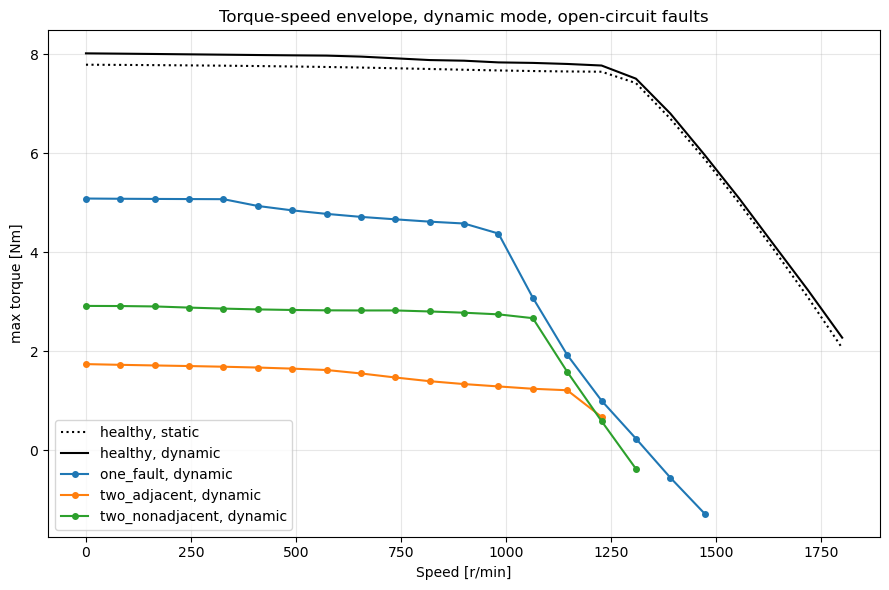

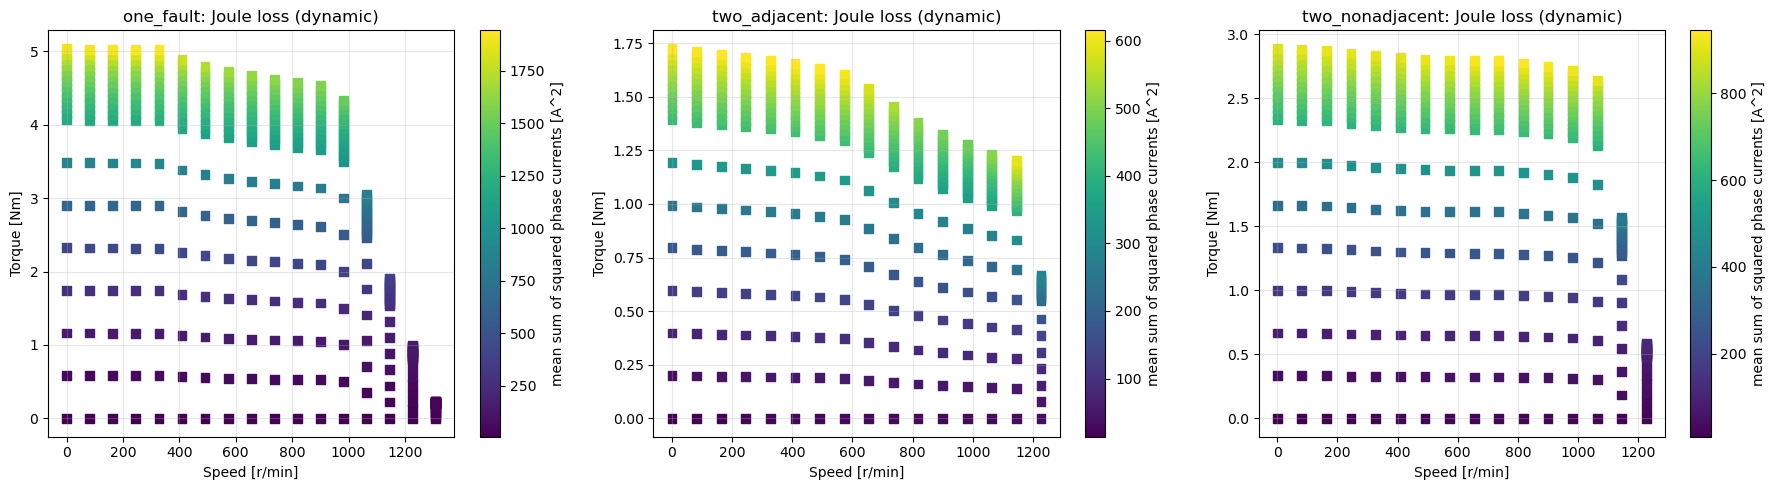

limit check over the solved cells (nodes and both segment ends):
  one_fault       : 357 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.000 V (limit 13.0), trajectories stored: True
  two_adjacent    : 335 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.000 V (limit 13.0), trajectories stored: True
  two_nonadjacent : 336 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.000 V (limit 13.0), trajectories stored: True


In [6]:
# Summary figures: envelopes (with the healthy maps of the same run tag, if computed), Joule loss, limits check
healthy_probe = os.path.join(data_dir, f"torque_speed_map_probe_neural_flux_torque_{run_tag.replace('_quick', '')}.pkl")
fig, ax = plt.subplots(figsize=(9, 6))
if os.path.isfile(healthy_probe):
    with open(healthy_probe, "rb") as f:
        hp = pickle.load(f)
    if len(hp["tmax_old_row"]) == N_OMEGA:
        ax.plot(rpm_vec, hp["tmax_static_row"], "k:", label="healthy, static")
        ax.plot(rpm_vec, hp["tmax_old_row"], "k-", label="healthy, dynamic")
for name, grid in results.items():
    ax.plot(rpm_vec, grid["probe_tmax"], "o-", ms=4, label=f"{name}, dynamic")
ax.set_xlabel("Speed [r/min]"); ax.set_ylabel("max torque [Nm]"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Torque-speed envelope, dynamic mode, open-circuit faults")
fig.tight_layout(); fig.savefig(os.path.join(summary_dir, "envelopes.png"), dpi=130); plt.show()

fig, axs = plt.subplots(1, len(results), figsize=(6 * len(results), 5), squeeze=False)
for ax, (name, grid) in zip(axs[0], results.items()):
    T2 = grid["grid_torq_neural"]
    O2 = np.broadcast_to(rpm_vec[None, :], T2.shape)
    ok = np.isfinite(grid["grid_joule_loss"])
    sc = ax.scatter(O2[ok], T2[ok], c=grid["grid_joule_loss"][ok], cmap="viridis", s=40 if N_TORQ > 10 else 300, marker="s")
    fig.colorbar(sc, ax=ax, label="mean sum of squared phase currents [A^2]")
    ax.set_title(f"{name}: Joule loss (dynamic)"); ax.set_xlabel("Speed [r/min]"); ax.set_ylabel("Torque [Nm]"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(summary_dir, "joule_loss_maps.png"), dpi=130); plt.show()

print("limit check over the solved cells (nodes and both segment ends):")
for name, grid in results.items():
    ok = np.isfinite(grid["grid_joule_loss"])
    print(f"  {name:16s}: {int(ok.sum())} cells solved, peak phase current {np.nanmax(grid['grid_curr_peak']):.3f} A (limit {CURR_MAX}), "
          f"peak phase voltage {np.nanmax(grid['grid_volt_peak']):.3f} V (limit {VOLT_MAX}), trajectories stored: {'curr_dq_traj' in grid}")

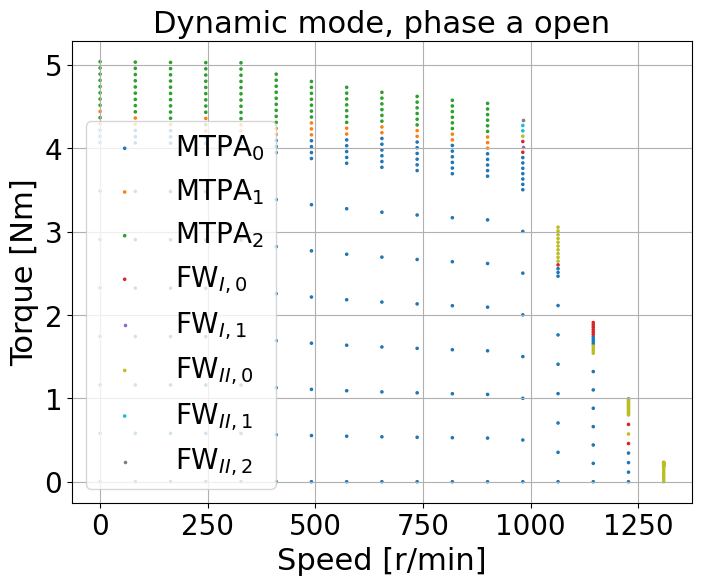

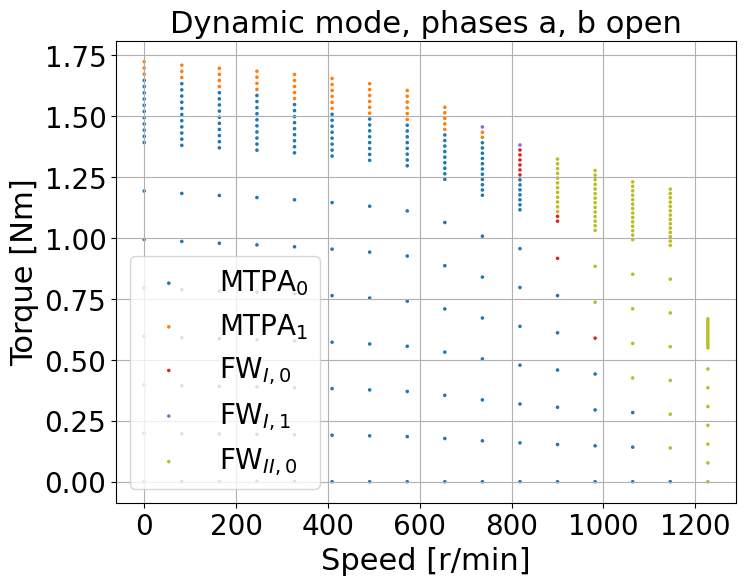

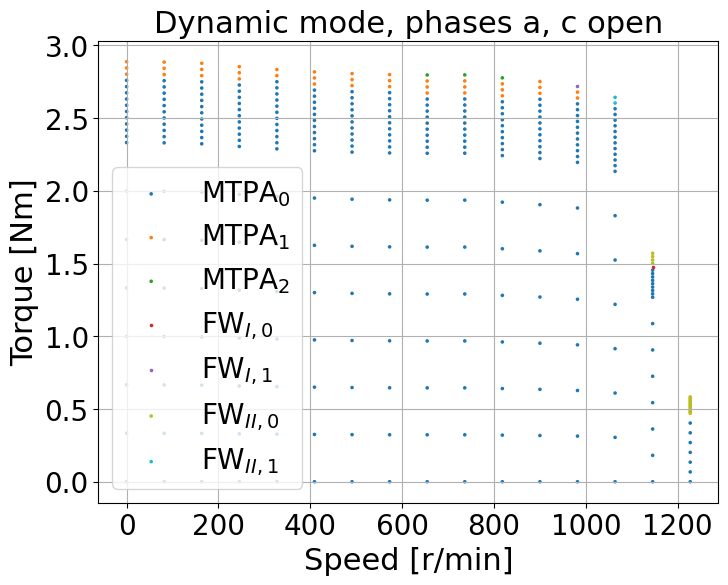

In [7]:
# Torque-speed maps of the dynamic fault-tolerant mode, one per fault case, plotted like the rest of the library
# (plot_grid_segments, as in the healthy map notebook), from the saved results -- nothing is recomputed.
from current_setpoints.optimization.data import grid_to_data
from current_setpoints.utils.plotting import plot_grid_segments

CASE_TITLES = {"one_fault": "phase a open", "two_adjacent": "phases a, b open", "two_nonadjacent": "phases a, c open"}
_show = plt.show  # plot_grid_segments shows its figure itself: save it on the way
try:
    for name in SCENARIOS:
        with open(os.path.join(data_dir, f"fault_map_dynamic_{name}_{run_tag}.pkl"), "rb") as f:
            grid = pickle.load(f)
        fpath = os.path.join(summary_dir, f"region_map_dynamic_{name}.png")
        plt.show = lambda *a, _p=fpath, **k: (plt.gcf().savefig(_p, dpi=130, bbox_inches="tight"), _show(*a, **k))
        plot_grid_segments(grid_to_data(grid, k_skip=1),
                           title=f"Dynamic mode, {CASE_TITLES[name]}",
                           override_torq_2d=grid["grid_torq_neural"])
finally:
    plt.show = _show
